# 06 — One-road results and model comparison
Run 05a first. Five descriptive charts can be generated even when the optional 05b classification has not been run. To see the two classifier charts and model metrics, run 05b and rerun this notebook. Charts are written locally to `charts/5000/`.

Games: 5,000; players: 20,000


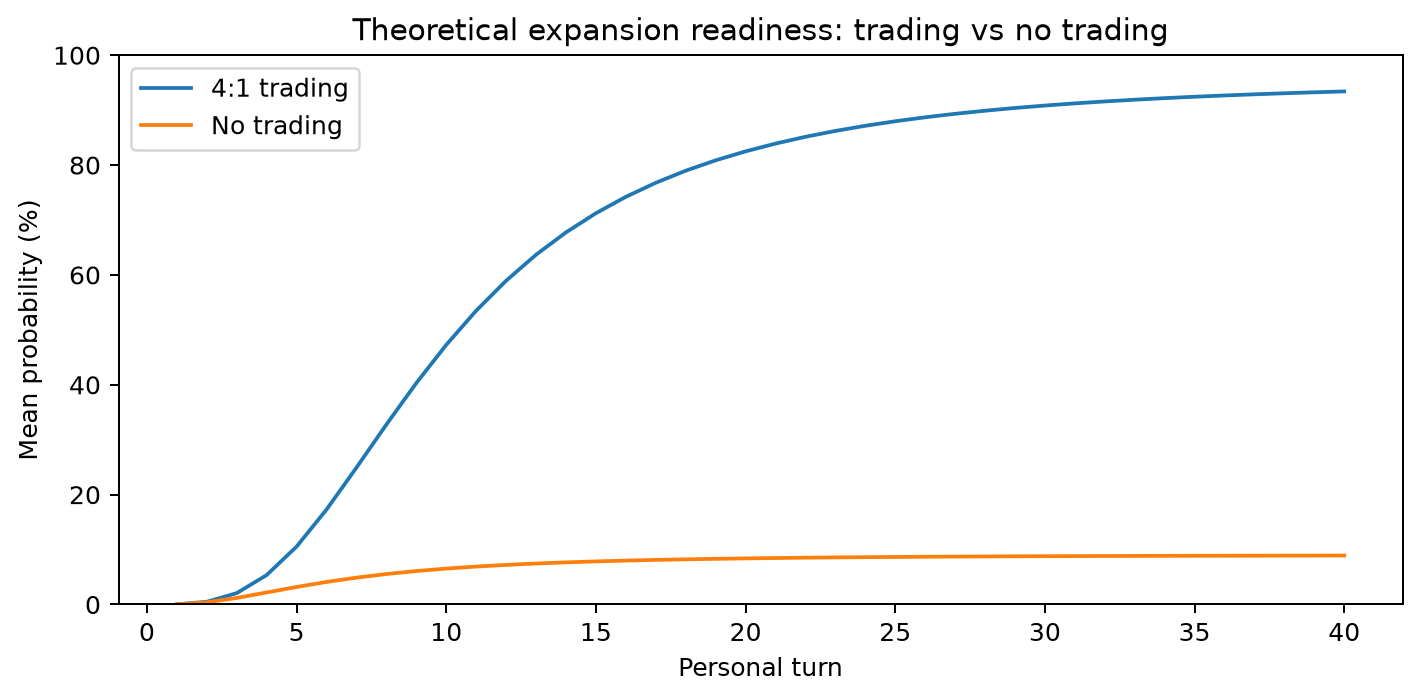

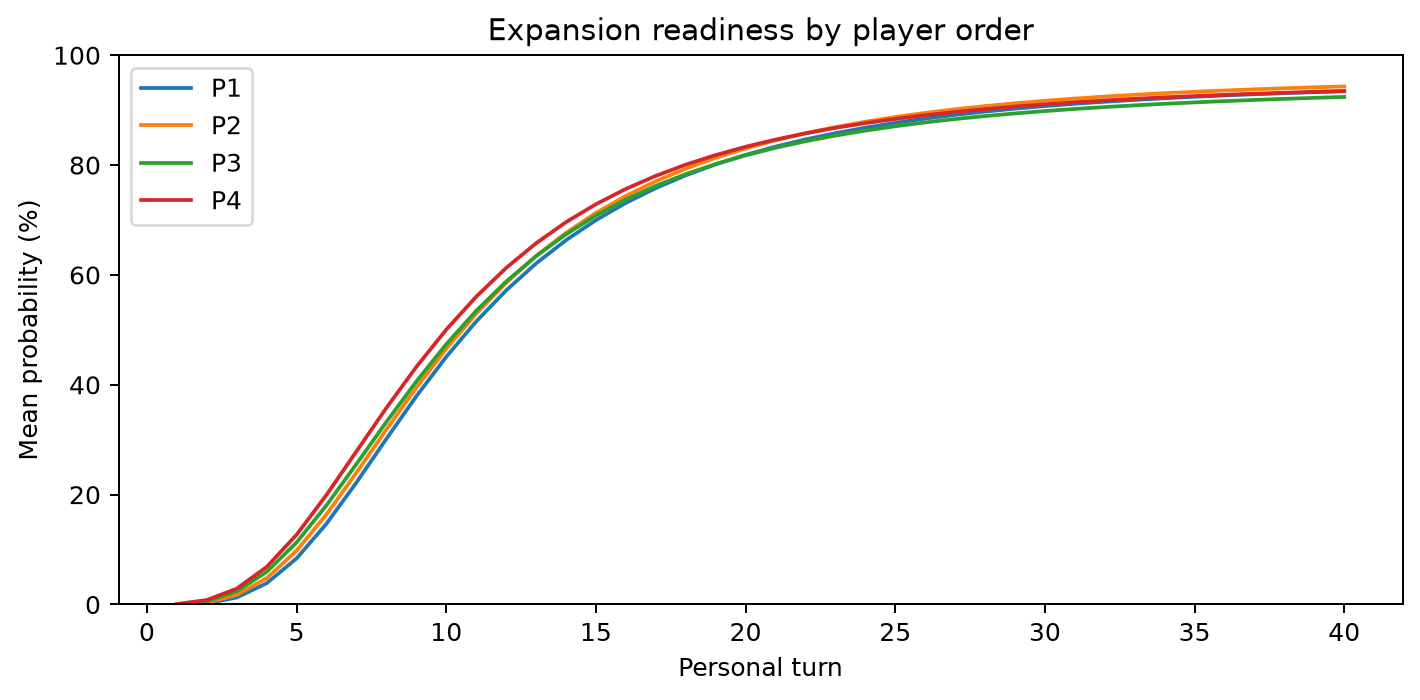

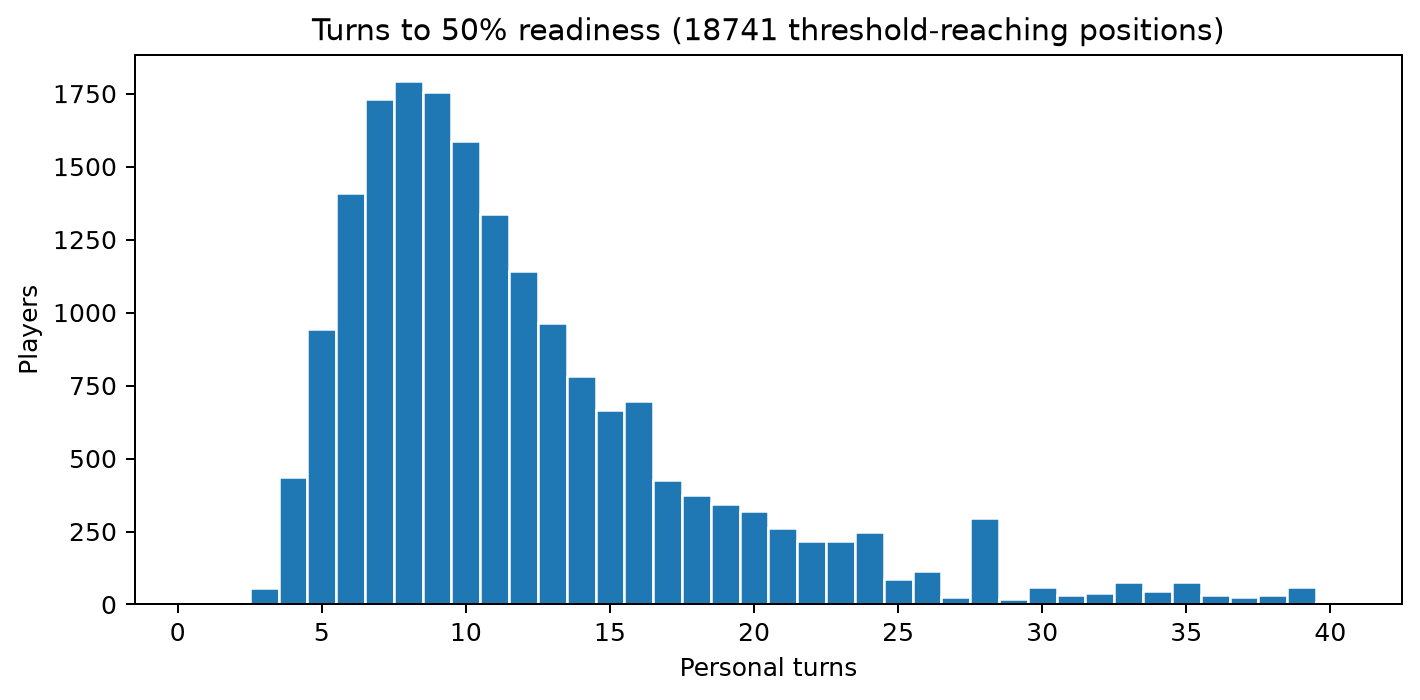

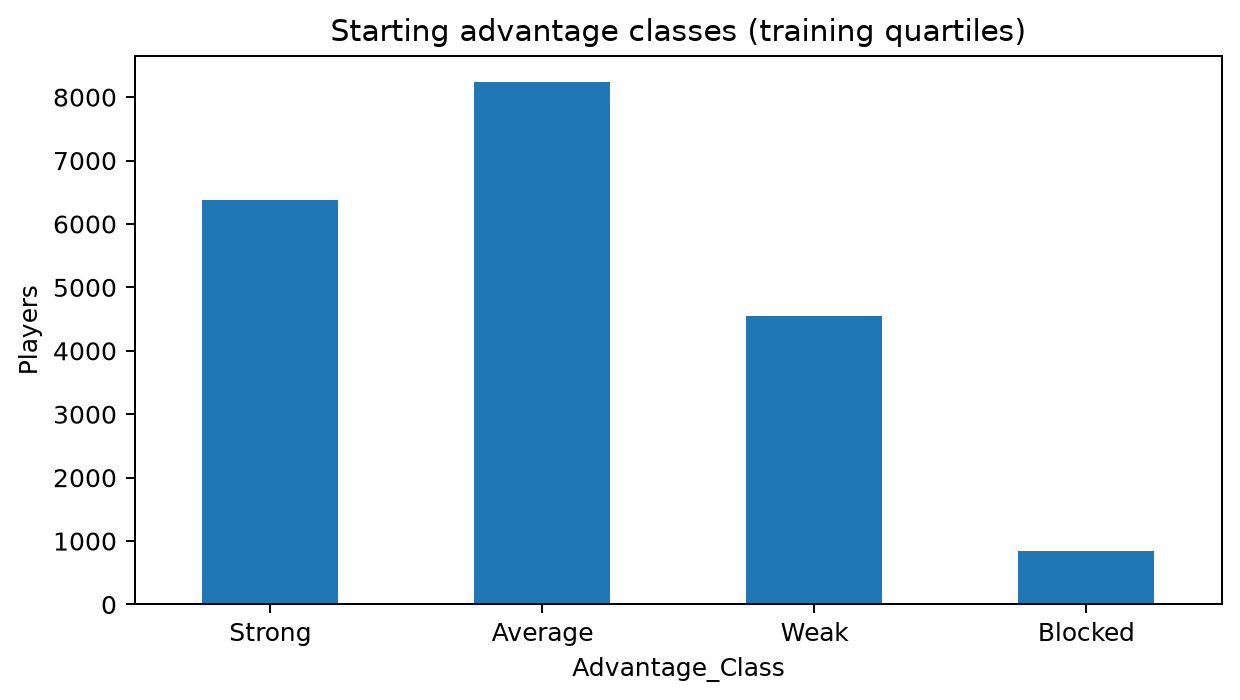

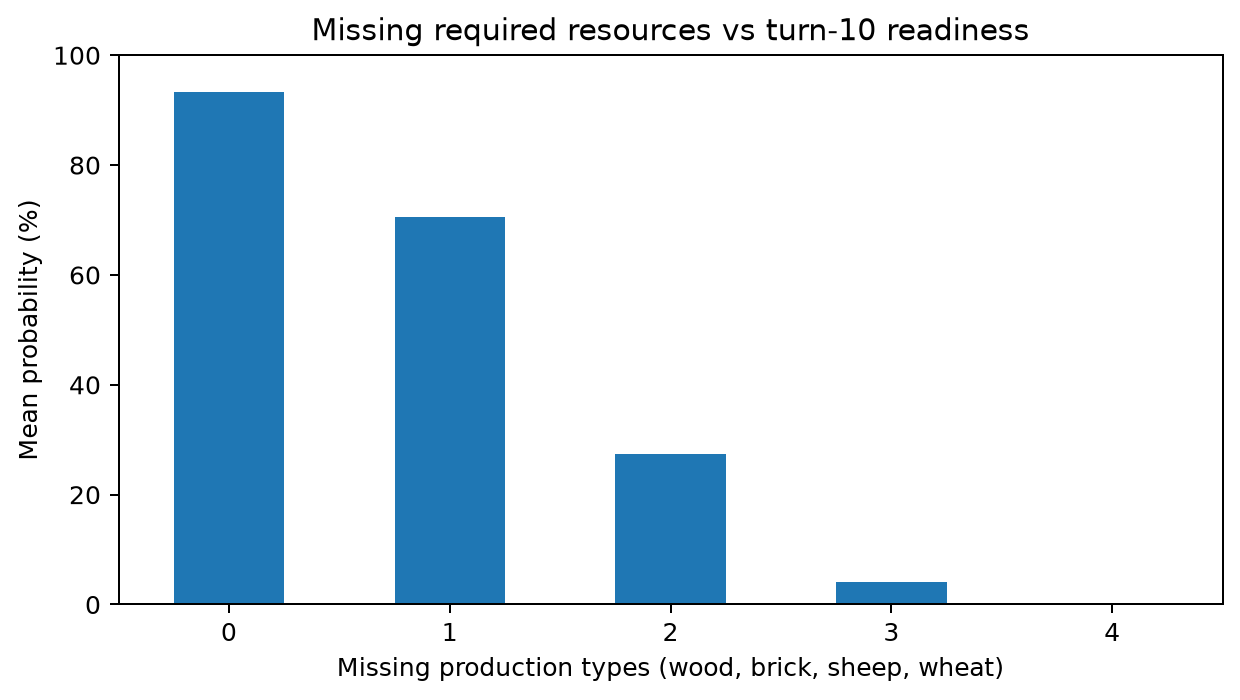

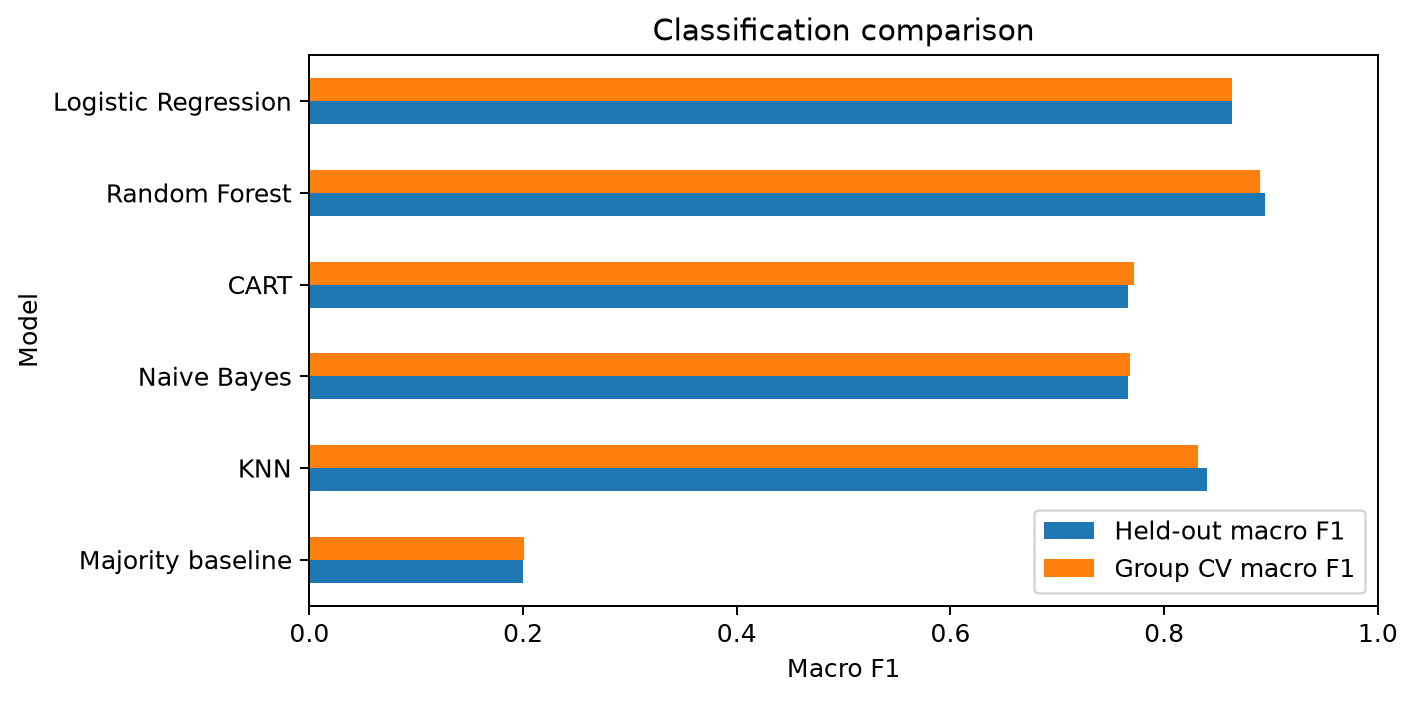

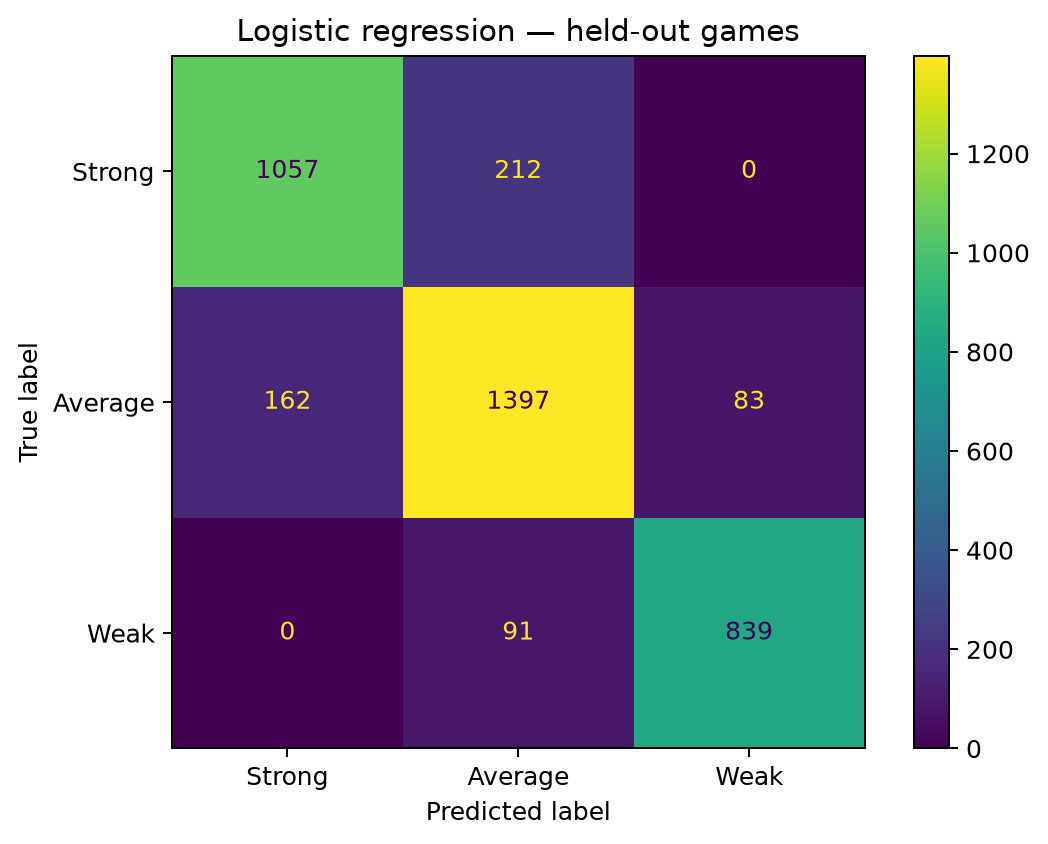

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from advantage_charts import charts
from experiment_io import OUT, read_required, validate_advantage, validate_players, same_players

d=validate_advantage(read_required(OUT,"starting_advantage.csv","05_starting_advantage.ipynb"))
p=validate_players(read_required(OUT,"initial_placements.csv","01_data_extraction.ipynb"))
assert same_players(d,p), "Starting advantage does not match the current placements. Rerun 05a."
print(f"Games: {d.Game_ID.nunique():,}; players: {len(d):,}")
CHARTS=Path("charts/5000")
created=charts(OUT,CHARTS)
for path in created:
    display(Image(filename=str(path)))

In [2]:
if (CHARTS/"06_model_comparison.png") in created:
    display(pd.read_csv(OUT/"advantage_classification_results.csv").sort_values("Macro_F1",ascending=False))
    display(pd.read_csv(OUT/"advantage_classification_cv.csv").sort_values("Macro_F1",ascending=False))
else:
    print("Classifier results not available for this dataset. Run 05_classification.ipynb to generate them.")

,Model,Accuracy,Balanced_Accuracy,Macro_F1
4,Random Forest,0.890653,0.888787,0.893974
5,Logistic Regression,0.857329,0.861961,0.863917
1,KNN,0.835460,0.835830,0.840202
2,Naive Bayes,0.759177,0.759477,0.766280
3,CART,0.761781,0.752977,0.766279
0,Majority baseline,0.427493,0.333333,0.199647


,Model,Accuracy,Balanced_Accuracy,Macro_F1,Accuracy_SD,Balanced_Accuracy_SD,Macro_F1_SD
4,Random Forest,0.887004,0.884569,0.890125,0.009013,0.008521,0.008298
5,Logistic Regression,0.856420,0.861923,0.863625,0.006128,0.005417,0.005790
1,KNN,0.826253,0.827943,0.831337,0.005120,0.004323,0.004937
3,CART,0.766910,0.761283,0.771915,0.007090,0.007517,0.007199
2,Naive Bayes,0.760595,0.762834,0.768197,0.007503,0.007881,0.007521
0,Majority baseline,0.429906,0.333333,0.200427,0.006029,0.000000,0.001966


If classification was skipped, the class distribution uses fixed pilot boundaries of 7 and 14 turns. If classification was completed, it uses its training-only quartiles. The variable-road analysis is in notebook 08.